# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** _______________________
**Группа:** _______________________
**Вариант:** ______ (тема модуля из ЛР № 1: _______________________)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

### Порядок выполнения

1. **Runtime → Change runtime type → T4 GPU.** Без GPU перевод 120 сегментов двумя моделями
   займёт часы.
2. Выполните блоки 0–1 (установка, окружение).
3. Блок 2 — подключите **свои** файлы из ЛР № 1 (`segments_en.csv`, `glossary.csv`,
   `aligned_reference.csv`) и убедитесь, что проверка объёма даёт «ГОТОВО».
4. Реализуйте функции в блоках 3–8 вместо маркеров `# TODO`.
5. Запустите блок 9 — все автотесты должны пройти без `AssertionError`.
6. Выполните блоки 10–15: перевод корпуса, QA, сравнение, **графики**, отчёт.
7. Заполните вручную колонки `preferred` и `comment` — автоматический выбор модели их не
   заменяет.

### Обязательный минимум

| Требование | Значение |
|---|---|
| Сегментов в корпусе, переведённых **каждой** моделью | **120+** |
| Терминов в глоссарии, разобранных токенизаторами | **100+** |
| Пар `source` / `reference` для кросс-энтропии | 5+ |
| Пар для анализа cross-attention | 2+ |
| Режимы инференса | последовательный и пакетный |
| Содержательных различий с аргументацией | 5+ |
| Графиков в отчёте | 4+ |

> Если в ЛР № 1 корпус меньше, расширьте исходный учебный модуль и глоссарий до требуемого
> объёма **до** начала работы: все дальнейшие выводы опираются на статистику, а на 15
> сегментах она недостоверна.

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** В `transformers` 5.x модели по умолчанию используют
  ускоренное внимание (SDPA/Flash), которое не сохраняет веса: `outputs.cross_attentions`
  окажется пустым, и блок 7 упадёт с `IndexError: tuple index out of range`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [ ]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [8]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.16
        torch: 2.11.0+cu130
 transformers: 5.22.0
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные своего варианта из ЛР № 1

Нужны три файла:

| Файл | Обязательные колонки | Объём |
|---|---|---|
| `data/segments_en.csv` | `segment_id`, `source` | не менее 120 сегментов |
| `data/glossary.csv` | `en`, `ru` | не менее 100 терминов |
| `data/aligned_reference.csv` | `segment_id`, `source`, `reference` | те же сегменты |

Способ 1 — загрузить файлы вручную (диалог выбора появится после запуска ячейки).
Способ 2 — раскомментировать монтирование Google Drive и указать путь к своей папке.
Если ничего не загружено, создаётся **демонстрационный** мини-набор: он годится только для
проверки автотестов, сдавать работу на нём нельзя.

In [9]:
# --- Способ 1: загрузка файлов с компьютера ---------------------------------
try:
    from google.colab import files

    print("Выберите segments_en.csv, glossary.csv, aligned_reference.csv "
          "(или закройте диалог, чтобы использовать демо-данные)")
    uploaded = files.upload()
    for name, content in uploaded.items():
        (DATA / name).write_bytes(content)
except Exception as error:  # noqa: BLE001 - вне Colab или диалог закрыт
    print("Загрузка пропущена:", error.__class__.__name__)

# --- Способ 2: Google Drive ------------------------------------------------
# from google.colab import drive
# drive.mount("/content/drive")
# import shutil
# for name in ("segments_en.csv", "glossary.csv", "aligned_reference.csv"):
#     shutil.copy(f"/content/drive/MyDrive/lab01/{name}", DATA / name)

# --- Демо-набор на случай отсутствия файлов --------------------------------
DEMO_PARALLEL = [
    ("A variable stores a value.", "Переменная хранит значение."),
    ("A condition controls which branch is executed.",
     "Условие определяет, какая ветвь выполняется."),
    ("A loop repeats a block of instructions.", "Цикл повторяет блок инструкций."),
    ("A function can return a value.", "Функция может возвращать значение."),
]
DEMO_GLOSSARY = [("variable", "переменная"), ("value", "значение"),
                 ("loop", "цикл"), ("function", "функция")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src}
                  for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref}
                  for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]
                 ).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

# --- проверка структуры (обязательна) --------------------------------------
assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), \
    "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), \
    "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"


def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    """Проверить готовность корпуса к сдаче и напечатать отчёт."""
    checks = [
        ("сегментов", len(segments), MIN_SEGMENTS),
        ("терминов", len(glossary), MIN_TERMS),
    ]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready


print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям"
      if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()

Выберите segments_en.csv, glossary.csv, aligned_reference.csv (или закройте диалог, чтобы использовать демо-данные)


Saving aligned_reference.csv to aligned_reference.csv
Saving glossary.csv to glossary.csv
Saving segments_en.csv to segments_en.csv

Проверка объёма корпуса:
  сегментов   120 / 120  ГОТОВО
  терминов    100 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 12.0 слов


,segment_id,source
0,s001,"Energy underpins all sectors of the economy, a..."
1,s002,Renewable Energy is derived from natural proce...
2,s003,Renewable energy technologies (RETs) are techn...
3,s004,Technology transfer is an important facet of R...
4,s005,Flow A depicts the process of hardware being c...


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Подсказки.** `AutoTokenizer.from_pretrained` / `AutoModelForSeq2SeqLM.from_pretrained`;
модель переносится на устройство методом `.to(device)` и переводится в режим инференса
`.eval()` — без этого включён dropout и результат нестабилен. Для NLLB токенизатору
передаются `src_lang` и `tgt_lang`.

**Обязательно:** передайте `attn_implementation="eager"` в `from_pretrained`, иначе блок 7
не получит веса внимания. Старые версии `transformers` этого аргумента не знают — оберните
вызов в `try / except (TypeError, ValueError)`.

In [16]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и подготовить её к инференсу."""
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)

    kwargs = {}
    if eager_attention:
        kwargs["attn_implementation"] = "eager"

    try:
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name, **kwargs)
    except (TypeError, ValueError):
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    model = model.to(device)
    model.eval()
    return tokenizer, model

## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Подсказки.** Токенизация пакета: `tokenizer(list_of_texts, return_tensors="pt",
padding=True, truncation=True).to(device)`. Генерация — под `torch.no_grad()`, декодирование —
`tokenizer.batch_decode(..., skip_special_tokens=True)`.

Для NLLB направление перевода задаётся аргументом `forced_bos_token_id`, который получают как
`tokenizer.convert_tokens_to_ids("rus_Cyrl")`. Без него язык результата не гарантирован.

In [17]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом."""
    inputs = tokenizer(list(texts), return_tensors="pt", padding=True, truncation=True).to(device)

    gen_kwargs = {"num_beams": num_beams, "max_new_tokens": max_new_tokens}
    if forced_bos_token_id is not None:
        gen_kwargs["forced_bos_token_id"] = forced_bos_token_id

    with torch.no_grad():
        outputs = model.generate(**inputs, **gen_kwargs)

    return tokenizer.batch_decode(outputs, skip_special_tokens=True)


def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному."""
    _ = translate_batch(texts[:1], tokenizer, model, device, **kwargs)
    start = time.perf_counter()
    translations = []
    for text in texts:
        res = translate_batch([text], tokenizer, model, device, **kwargs)
        translations.extend(res)
    end = time.perf_counter()
    return translations, end - start


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками."""
    _ = translate_batch(texts[:batch_size], tokenizer, model, device, **kwargs)
    start = time.perf_counter()
    translations = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        res = translate_batch(batch, tokenizer, model, device, **kwargs)
        translations.extend(res)
    end = time.perf_counter()
    return translations, end - start

## Блок 5. Субсловная токенизация (шаги 3, 10)

**Подсказка.** `tokenizer(term, add_special_tokens=False)["input_ids"]`, затем
`tokenizer.convert_ids_to_tokens(ids)`. Специальные токены отключаются намеренно: иначе в
разборе появятся `</s>` и код языка.

In [23]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any, label: str) -> pd.DataFrame:
    """Разобрать термины токенизатором модели."""
    records = []
    for term in terms:

        ids = tokenizer(term, add_special_tokens=False)["input_ids"]
        tokens = tokenizer.convert_ids_to_tokens(ids)


        n_words = len(term.split())

        records.append({
            "model": label,
            "term": term,
            "n_words": n_words,
            "n_tokens": len(tokens),
            "tokens": " ".join(tokens),
            "is_word_level": len(tokens) == n_words
        })
    return pd.DataFrame(records)

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Подсказка.** Эталон передаётся в токенизатор аргументом `text_target=...`; при прямом вызове
модели `model(**batch)` поле `outputs.loss` уже содержит усреднённую кросс-энтропию.

In [26]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источнике."""
    batch = tokenizer(source, text_target=target, return_tensors="pt", padding=True, truncation=True).to(device)

    with torch.no_grad():
        outputs = model(**batch)

    return float(outputs.loss.item())

## Блок 7. Cross-attention (шаг 7)

**Подсказки.** Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [28]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention.

    Returns:
        Кортеж ``(frame, shape)``: матрица внимания и исходная форма тензора.
    """
    # Токенизируем пару (источник, эталон)
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      padding=True, truncation=True).to(device)

    with torch.no_grad():
        outputs = model(**batch, output_attentions=True, return_dict=True)

    if not outputs.cross_attentions:
        raise RuntimeError("Модель не вернула веса внимания (нужен attn_implementation='eager')")

    # Берем нужный слой внимания
    attn = outputs.cross_attentions[layer]
    shape = tuple(attn.shape)

    # Усредняем по головам (heads) и берем первый элемент батча
    attn_avg = attn[0].mean(dim=0).cpu().numpy()

    # Получаем ID токенов
    src_ids = batch["input_ids"][0].cpu().tolist()
    tgt_ids = batch["labels"][0].cpu().tolist()

    # Убираем игнорируемые токены (padding -100)
    tgt_ids = [tid for tid in tgt_ids if tid != -100]

    # Переводим ID в читаемые токены
    src_tokens = tokenizer.convert_ids_to_tokens(src_ids, skip_special_tokens=True)
    tgt_tokens = tokenizer.convert_ids_to_tokens(tgt_ids, skip_special_tokens=True)

    # Обрезаем матрицу под реальные длины (без спецтокенов)
    attn_avg = attn_avg[:len(tgt_tokens), :len(src_tokens)]

    # Создаем таблицу
    frame = pd.DataFrame(attn_avg, index=tgt_tokens, columns=src_tokens)
    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Подсказки.** Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [34]:
import re

def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, которые есть в источнике, но отсутствуют в переводе."""
    violations = []
    source_lower = source.lower()
    trans_lower = translation.lower()

    for _, row in glossary.iterrows():
        en = str(row["en"]).lower()
        ru = str(row["ru"]).lower()

        # Проверяем, есть ли английский термин в исходнике (по границам слов)
        if re.search(rf"\b{re.escape(en)}\b", source_lower):
            # Берем корень русского слова (первые 5 букв), чтобы игнорировать падежи
            ru_root = ru[:5] if len(ru) >= 5 else ru
            if ru_root not in trans_lower:
                violations.append({"source_term": row["en"], "preferred_ru": row["ru"]})

    return violations


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в JSON Lines."""
    with open(path, "w", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return path


def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей."""
    rows = []
    for i in range(len(marian_records)):
        m_rec = marian_records[i]
        n_rec = nllb_records[i]
        ref = references[i]

        rows.append({
            "segment_id": m_rec["id"],
            "source": m_rec["source"],
            "marian": m_rec["translation"],
            "nllb": n_rec["translation"],
            "reference": ref,
            "identical": m_rec["translation"] == n_rec["translation"],
            "preferred": "",
            "comment": ""
        })
    return pd.DataFrame(rows)

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [ ]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

In [19]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  307MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [24]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,access to modern energy services,5,5,▁access ▁to ▁modern ▁energy ▁services,True
1,MarianMT,renewable energy,2,2,▁renewable ▁energy,True
2,MarianMT,renewable energy technologies,3,3,▁renewable ▁energy ▁technologies,True
3,MarianMT,technology transfer,2,2,▁technology ▁transfer,True
4,MarianMT,hardware,1,1,▁hardware,True


In [27]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 0.4847, шум 6.5663


In [29]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 24, 22), матрица (23, 21)


,▁Energy,▁underpin,s,▁all,▁sectors,▁of
▁Эн,0.643,0.081,0.017,0.089,0.004,0.002
е,0.225,0.007,0.008,0.002,0.002,0.000
рг,0.242,0.010,0.008,0.002,0.001,0.000
ия,0.152,0.009,0.021,0.001,0.001,0.001
▁лежит,0.007,0.510,0.153,0.012,0.007,0.007


In [30]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

Замерьте оба режима на всех своих сегментах и сохраните `results/timing.csv`. Первый вызов не
включайте в замер: он содержит инициализацию вычислителя. Полезно сравнить несколько размеров
пачки (4, 8, 16) — выигрыш насыщается.

In [31]:
sources = segments_df["source"].tolist()

# Прогрев (первый вызов всегда медленный)
_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)

print("1. Замер последовательного перевода...")
seq_out, seq_time = timed_sequential(sources, marian_tokenizer, marian_model, DEVICE)

print("2. Замер пакетного перевода (batch_size=4)...")
b4_out, b4_time = timed_batched(sources, marian_tokenizer, marian_model, DEVICE, batch_size=4)

print("3. Замер пакетного перевода (batch_size=8)...")
b8_out, b8_time = timed_batched(sources, marian_tokenizer, marian_model, DEVICE, batch_size=8)

print("4. Замер пакетного перевода (batch_size=16)...")
b16_out, b16_time = timed_batched(sources, marian_tokenizer, marian_model, DEVICE, batch_size=16)

# Собираем таблицу
timing_data = [
    {"model": "MarianMT", "mode": "sequential", "batch_size": 1, "n_segments": len(sources), "total_s": seq_time, "per_segment_s": seq_time/len(sources), "device": str(DEVICE), "speedup": 1.0},
    {"model": "MarianMT", "mode": "batched", "batch_size": 4, "n_segments": len(sources), "total_s": b4_time, "per_segment_s": b4_time/len(sources), "device": str(DEVICE), "speedup": seq_time/b4_time},
    {"model": "MarianMT", "mode": "batched", "batch_size": 8, "n_segments": len(sources), "total_s": b8_time, "per_segment_s": b8_time/len(sources), "device": str(DEVICE), "speedup": seq_time/b8_time},
    {"model": "MarianMT", "mode": "batched", "batch_size": 16, "n_segments": len(sources), "total_s": b16_time, "per_segment_s": b16_time/len(sources), "device": str(DEVICE), "speedup": seq_time/b16_time},
]

timing_df = pd.DataFrame(timing_data)
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

print("\nРезультаты замера:")
display(timing_df[["mode", "batch_size", "total_s", "speedup"]])

matches = sum(1 for a, b in zip(seq_out, b8_out) if a == b)
print(f"\nСовпало переводов (последовательно vs batch_size=8): {matches} из {len(sources)}")

1. Замер последовательного перевода...
2. Замер пакетного перевода (batch_size=4)...
3. Замер пакетного перевода (batch_size=8)...
4. Замер пакетного перевода (batch_size=16)...

Результаты замера:


,mode,batch_size,total_s,speedup
0,sequential,1,26.391800,1.000000
1,batched,4,9.618996,2.743717
2,batched,8,4.956698,5.324472
3,batched,16,3.320283,7.948659



Совпало переводов (последовательно vs batch_size=8): 120 из 120


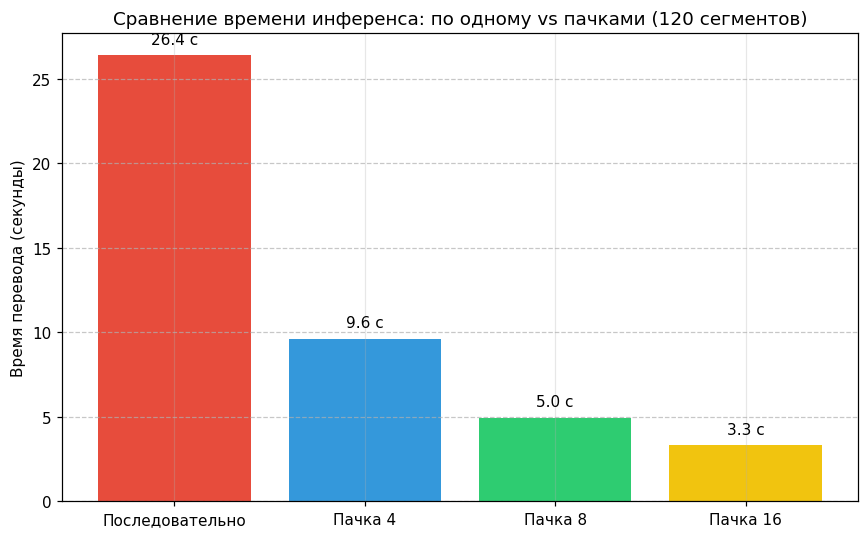

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

# Берем данные из нашей таблицы timing_df, которую мы только что создали
x_labels = ["Последовательно", "Пачка 4", "Пачка 8", "Пачка 16"]
times = timing_df["total_s"].values

# Рисуем столбцы разными цветами
bars = ax.bar(x_labels, times, color=['#e74c3c', '#3498db', '#2ecc71', '#f1c40f'])

# Подписываем каждый столбец значением времени
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{yval:.1f} с", ha='center', va='bottom')

ax.set_ylabel("Время перевода (секунды)")
ax.set_title("Сравнение времени инференса: по одному vs пачками (120 сегментов)")
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
# Сохраняем график в папку figures
plt.savefig(FIGURES / "timing.png", dpi=150)
plt.show()

**Что получено (заполните после запуска):** время последовательного и пакетного режима,
ускорение, число сегментов, где режимы дали разный перевод. Объясните, почему выигрыш
насыщается при росте `batch_size`.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

In [35]:
print("Перевод всех сегментов моделью MarianMT...")
marian_translations, _ = timed_batched(sources, marian_tokenizer, marian_model, DEVICE, batch_size=16)

marian_records = []
for i, (src, trans) in enumerate(zip(sources, marian_translations)):
    marian_records.append({
        "id": segments_df.iloc[i]["segment_id"],
        "source": src,
        "translation": trans,
        "model": MARIAN_NAME
    })

print("Перевод всех сегментов моделью NLLB...")
# Для NLLB обязательно передаем forced_bos_token_id=RUS_ID
nllb_translations, _ = timed_batched(sources, nllb_tokenizer, nllb_model, DEVICE, batch_size=16, forced_bos_token_id=RUS_ID)

nllb_records = []
for i, (src, trans) in enumerate(zip(sources, nllb_translations)):
    nllb_records.append({
        "id": segments_df.iloc[i]["segment_id"],
        "source": src,
        "translation": trans,
        "model": NLLB_NAME
    })

# Сохраняем результаты в JSONL
write_jsonl(marian_records, RESULTS / "results_marian.jsonl")
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

print("Готово! Файлы сохранены.")
print("\nПримеры переводов (первые 3 шт):")
for i in range(3):
    print(f"\n[{marian_records[i]['id']}]")
    print(f"EN: {marian_records[i]['source']}")
    print(f"Marian: {marian_records[i]['translation']}")
    print(f"NLLB:   {nllb_records[i]['translation']}")

Перевод всех сегментов моделью MarianMT...
Перевод всех сегментов моделью NLLB...
Готово! Файлы сохранены.

Примеры переводов (первые 3 шт):

[s001]
EN: Energy underpins all sectors of the economy, and improved access to modern energy services is central to development.
Marian: Энергетика лежит в основе всех секторов экономики, и улучшение доступа к современным энергетическим услугам имеет центральное значение для развития.
NLLB:   Энергия является основой всех секторов экономики, и улучшение доступа к современным энергетическим услугам является ключевым фактором развития.

[s002]
EN: Renewable Energy is derived from natural processes that are replenished constantly.
Marian: Возобновляемые источники энергии получают из природных процессов, которые постоянно пополняются.
NLLB:   Возобновляемая энергия получается из естественных процессов, которые постоянно пополняются.

[s003]
EN: Renewable energy technologies (RETs) are technologies that provide modern energy services.
Marian: Технолог

**Что получено (заполните после запуска):** число переведённых сегментов каждой моделью
и 2–3 примера расхождений, замеченных при беглом просмотре.

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

In [36]:
# Разбираем термины токенизатором NLLB
nllb_tokens_df = tokenize_terms(glossary_df["en"].tolist(), nllb_tokenizer, "NLLB")

# Объединяем таблицу MarianMT (которую мы сделали в Тесте 3) и NLLB
combined_tokens_df = pd.concat([tokens_df, nllb_tokens_df], ignore_index=True)
combined_tokens_df.to_csv(RESULTS / "tokenization_10_terms.csv", index=False, encoding="utf-8-sig")

# Выводим информацию о токенизаторах
print(f"Класс токенизатора Marian: {type(marian_tokenizer).__name__}, словарь: {marian_tokenizer.vocab_size}")
print(f"Класс токенизатора NLLB:   {type(nllb_tokenizer).__name__}, словарь: {nllb_tokenizer.vocab_size}")

# Считаем среднее число токенов
print(f"\nСреднее число токенов на термин:")
print(f"Marian: {tokens_df['n_tokens'].mean():.2f}")
print(f"NLLB:   {nllb_tokens_df['n_tokens'].mean():.2f}")

# Ищем термины, где разница в токенизации самая большая
pivot = combined_tokens_df.pivot(index="term", columns="model", values="n_tokens").dropna()
pivot["diff"] = abs(pivot["MarianMT"] - pivot["NLLB"])
top_diff = pivot.sort_values("diff", ascending=False).head(3)

print("\nТермины с наибольшей разницей в разбиении:")
for term, row in top_diff.iterrows():
    print(f"  {term}: MarianMT={int(row['MarianMT'])} токенов, NLLB={int(row['NLLB'])} токенов")

Класс токенизатора Marian: MarianTokenizer, словарь: 62518
Класс токенизатора NLLB:   NllbTokenizer, словарь: 256204

Среднее число токенов на термин:
Marian: 2.70
NLLB:   3.45

Термины с наибольшей разницей в разбиении:
  Nationally Determined Contributions: MarianMT=4 токенов, NLLB=7 токенов
  distributed renewable energy: MarianMT=3 токенов, NLLB=6 токенов
  renewable energy targets: MarianMT=3 токенов, NLLB=6 токенов


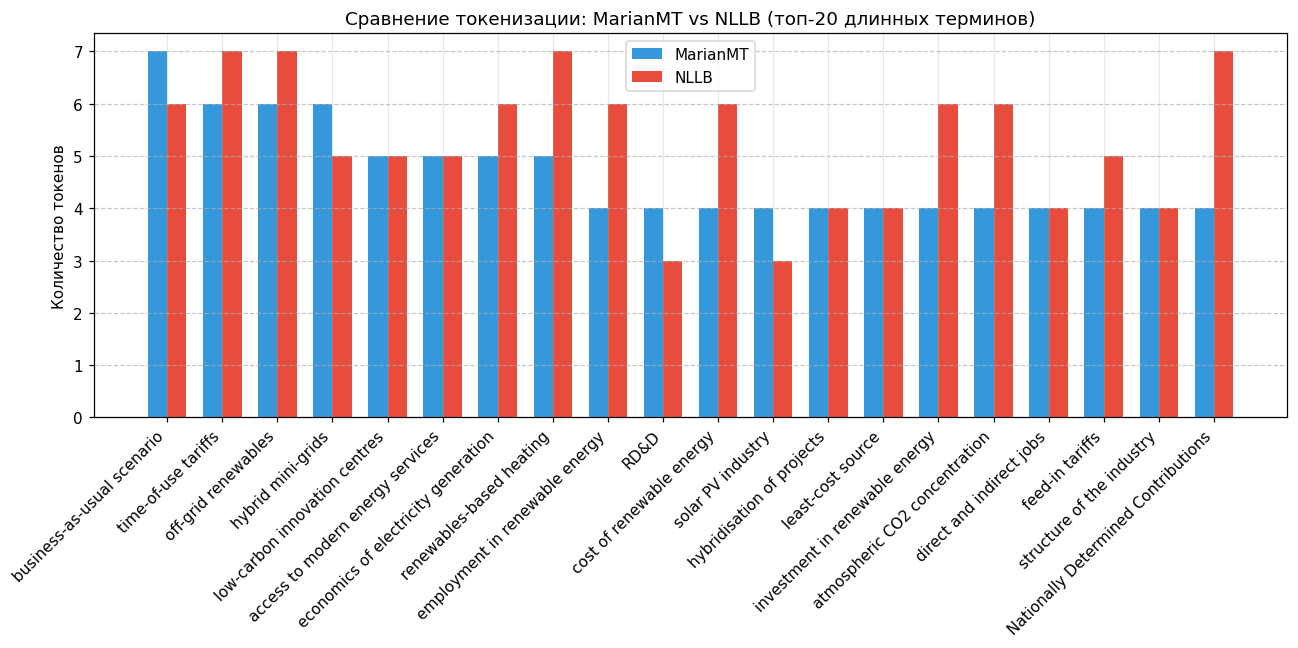

In [37]:
# ГРАФИК 2. Сравнение дробления терминов
import matplotlib.pyplot as plt

# Берем 20 самых показательных терминов (где больше всего токенов)
top20 = pivot.sort_values("MarianMT", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(top20))
width = 0.35

# Два столбца рядом: Marian и NLLB
bars1 = ax.bar([i - width/2 for i in x], top20["MarianMT"], width, label='MarianMT', color='#3498db')
bars2 = ax.bar([i + width/2 for i in x], top20["NLLB"], width, label='NLLB', color='#e74c3c')

ax.set_ylabel('Количество токенов')
ax.set_title('Сравнение токенизации: MarianMT vs NLLB (топ-20 длинных терминов)')
ax.set_xticks(x)
ax.set_xticklabels(top20.index, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES / "tokenization_comparison.png", dpi=150)
plt.show()

**Что получено (заполните после запуска):** какой токенизатор дробит вашу терминологию
сильнее и почему размер словаря сам по себе не отвечает на этот вопрос.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

In [38]:
# 1. Считаем loss для 5 пар
loss_rows = []
for i in range(5):
    src = marian_records[i]["source"]
    ref = aligned_df.iloc[i]["reference"]
    m_out = marian_records[i]["translation"]

    # Loss для эталона (правильный перевод)
    loss_ref = sequence_cross_entropy(src, ref, marian_tokenizer, marian_model, DEVICE)
    # Loss для собственного вывода модели
    loss_own = sequence_cross_entropy(src, m_out, marian_tokenizer, marian_model, DEVICE)

    loss_rows.append({
        "segment_id": marian_records[i]["id"],
        "source": src,
        "reference": ref,
        "marian_output": m_out,
        "loss_reference": loss_ref,
        "loss_own_output": loss_own,
        "gap": loss_own - loss_ref
    })

loss_df = pd.DataFrame(loss_rows)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")
print("Таблица loss сохранена:")
display(loss_df[["segment_id", "loss_reference", "loss_own_output"]])

# 2. Извлекаем cross-attention для 2 пар
attention_summary = []
for i in range(2):
    src = marian_records[i]["source"]
    ref = aligned_df.iloc[i]["reference"]
    seg_id = marian_records[i]["id"]

    frame, shape = extract_cross_attention(src, ref, marian_tokenizer, marian_model, DEVICE)
    frame.to_csv(RESULTS / f"attention_marian_{seg_id}.csv", encoding="utf-8-sig")

    attention_summary.append({
        "segment_id": seg_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": shape[2],
        "source_len": shape[3],
        "mean_max_weight": float(frame.max().max())
    })

attn_df = pd.DataFrame(attention_summary)
attn_df.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")
print("\nСводка по вниманию сохранена:")
display(attn_df)

Таблица loss сохранена:


,segment_id,loss_reference,loss_own_output
0,s001,0.484673,0.324644
1,s002,1.087379,0.399107
2,s003,0.839152,0.394008
3,s004,0.345571,0.345571
4,s005,1.479484,0.515229



Сводка по вниманию сохранена:


,segment_id,tensor_shape,n_heads,target_len,source_len,mean_max_weight
0,s001,"(1, 8, 24, 22)",8,24,22,0.681769
1,s002,"(1, 8, 17, 14)",8,17,14,0.598497


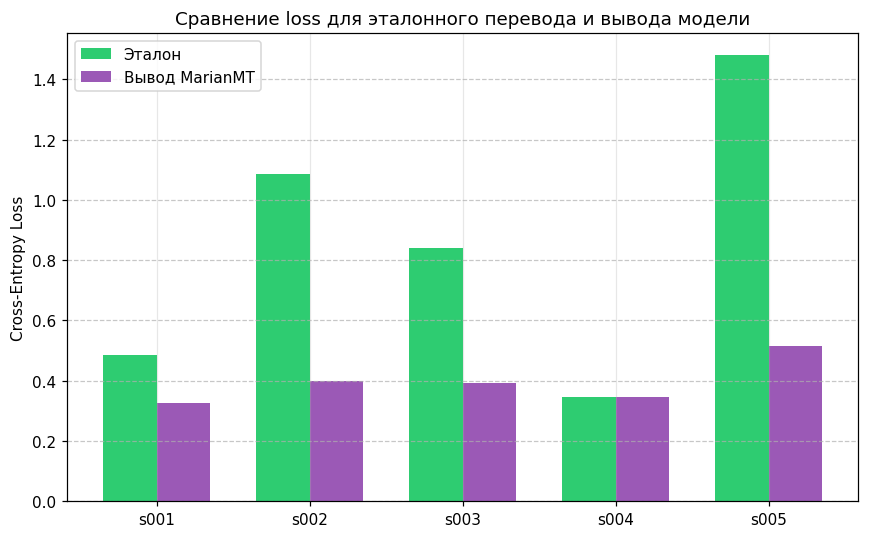

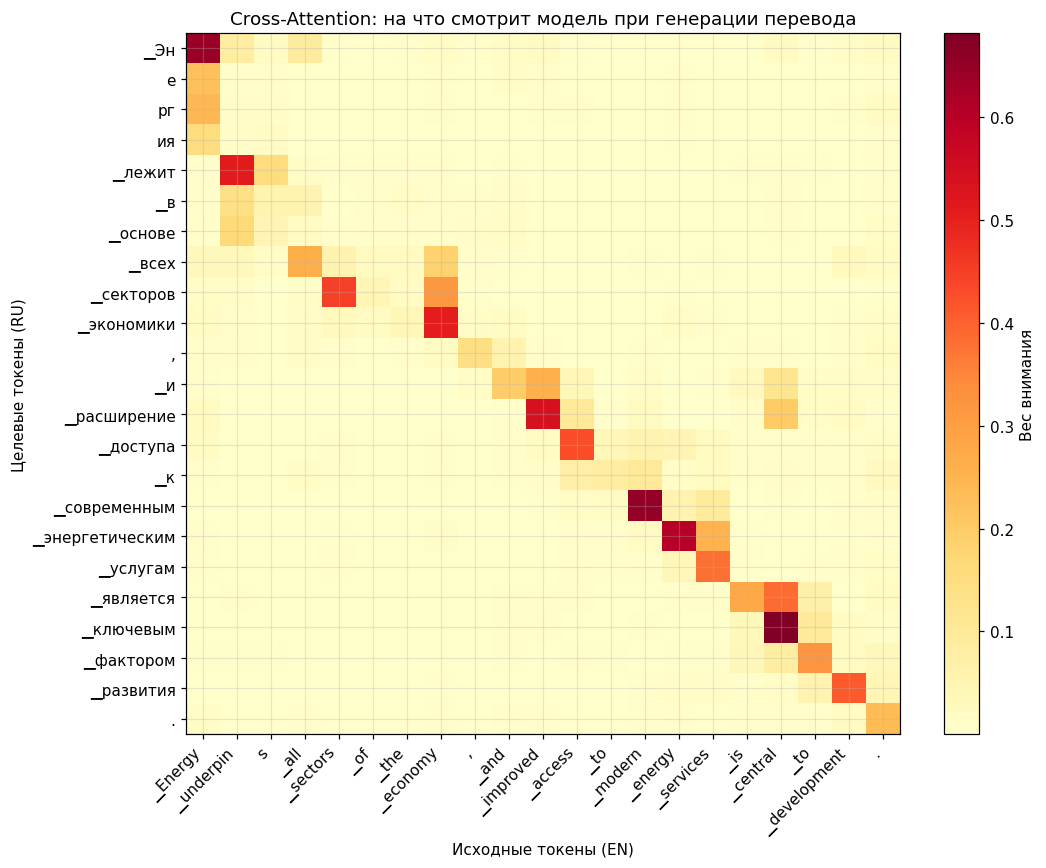

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# ГРАФИК 3. Сравнение loss эталона и вывода модели
# ==========================================
fig, ax = plt.subplots(figsize=(8, 5))
x = range(len(loss_df))
width = 0.35

ax.bar([i - width/2 for i in x], loss_df["loss_reference"], width, label='Эталон', color='#2ecc71')
ax.bar([i + width/2 for i in x], loss_df["loss_own_output"], width, label='Вывод MarianMT', color='#9b59b6')

ax.set_ylabel('Cross-Entropy Loss')
ax.set_title('Сравнение loss для эталонного перевода и вывода модели')
ax.set_xticks(x)
ax.set_xticklabels(loss_df["segment_id"])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES / "loss.png", dpi=150)
plt.show()


# ==========================================
# ГРАФИК 4. Тепловая карта cross-attention
# ==========================================
# Берем матрицу внимания для первого сегмента (s001)
frame, shape = extract_cross_attention(
    marian_records[0]["source"],
    aligned_df.iloc[0]["reference"],
    marian_tokenizer, marian_model, DEVICE
)

fig2, ax2 = plt.subplots(figsize=(10, 8))
# Рисуем тепловую карту
cax = ax2.imshow(frame.values, cmap='YlOrRd', aspect='auto')

# Подписываем оси токенами
ax2.set_xticks(np.arange(len(frame.columns)))
ax2.set_yticks(np.arange(len(frame.index)))
ax2.set_xticklabels(frame.columns, rotation=45, ha='right')
ax2.set_yticklabels(frame.index)

ax2.set_xlabel('Исходные токены (EN)')
ax2.set_ylabel('Целевые токены (RU)')
ax2.set_title('Cross-Attention: на что смотрит модель при генерации перевода')

fig2.colorbar(cax, label='Вес внимания')
plt.tight_layout()
plt.savefig(FIGURES / "cross_attention.png", dpi=150)
plt.show()

**Что получено (заполните после запуска):** соотношение loss эталона и собственного
вывода, сегмент с наибольшим разрывом и его причина; форма тензора внимания и то, что видно
на тепловой карте (диагональ, отклонения, вес служебных токенов).

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

In [40]:
# Проверяем соблюдение терминов для обеих моделей
qa_rows = []

for i in range(len(marian_records)):
    src = marian_records[i]["source"]
    seg_id = marian_records[i]["id"]
    m_out = marian_records[i]["translation"]
    n_out = nllb_records[i]["translation"]

    # Проверяем MarianMT
    violations_m = term_compliance(src, m_out, glossary_df)
    for v in violations_m:
        qa_rows.append({
            "segment_id": seg_id,
            "model": "MarianMT",
            "source_term": v["source_term"],
            "preferred_ru": v["preferred_ru"],
            "translation": m_out,
            "confirmed": "",  # заполним вручную
            "comment": ""
        })

    # Проверяем NLLB
    violations_n = term_compliance(src, n_out, glossary_df)
    for v in violations_n:
        qa_rows.append({
            "segment_id": seg_id,
            "model": "NLLB",
            "source_term": v["source_term"],
            "preferred_ru": v["preferred_ru"],
            "translation": n_out,
            "confirmed": "",
            "comment": ""
        })

glossary_qa_df = pd.DataFrame(qa_rows)
glossary_qa_df.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Найдено потенциальных нарушений терминологии: {len(glossary_qa_df)}")
display(glossary_qa_df.head(10))

Найдено потенциальных нарушений терминологии: 38


,segment_id,model,source_term,preferred_ru,translation,confirmed,comment
0,s005,MarianMT,hardware,технические средства,Поток А описывает процесс создания и использов...,,
1,s005,NLLB,hardware,технические средства,Flow A описывает процесс создания и введения в...,,
2,s009,MarianMT,low-carbon innovation centres,низкоуглеродные инновационные центры,Одним из вариантов развития этих местных знани...,,
3,s016,MarianMT,price distortion,ценовое искажение,"Таким образом, такое искажение цен ведет к сок...",,
4,s016,NLLB,price distortion,ценовое искажение,"Таким образом, это искажение цен уменьшает пер...",,
5,s017,MarianMT,feed-in tariffs,стимулирующие тарифы,Важным механизмом внутренней политики является...,,
6,s017,NLLB,feed-in tariffs,стимулирующие тарифы,Тарифы также являются важным механизмом внутре...,,
7,s021,MarianMT,technological progress,научно-технический прогресс,Быстрый технологический прогресс в сочетании с...,,
8,s021,NLLB,technological progress,научно-технический прогресс,"Быстрый технологический прогресс, в сочетании ...",,
9,s023,MarianMT,niche,нишевое решение,"Технология, которая когда-то рассматривалась в...",,


In [41]:
# 1. Строим таблицу
comparison_df = build_comparison_table(
    marian_records,
    nllb_records,
    aligned_df["reference"].tolist()
)

# 2. Сохраняем её
comparison_df.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")
print(f"Сводная таблица сохранена. Всего сегментов: {len(comparison_df)}")

# 3. Выводим 5 примеров, где переводы моделей разошлись (чтобы тебе было что анализировать)
diff_df = comparison_df[comparison_df["identical"] == False]
print("\nПримеры расхождений (первые 5):")
display(diff_df[["segment_id", "source", "marian", "nllb"]].head(5))

Сводная таблица сохранена. Всего сегментов: 120

Примеры расхождений (первые 5):


,segment_id,source,marian,nllb
0,s001,"Energy underpins all sectors of the economy, a...",Энергетика лежит в основе всех секторов эконом...,Энергия является основой всех секторов экономи...
1,s002,Renewable Energy is derived from natural proce...,Возобновляемые источники энергии получают из п...,Возобновляемая энергия получается из естествен...
2,s003,Renewable energy technologies (RETs) are techn...,Технологии использования возобновляемых источн...,Технологии возобновляемых источников энергии (...
3,s004,Technology transfer is an important facet of R...,Передача технологии является важным аспектом в...,Передача технологий является важным аспектом в...
4,s005,Flow A depicts the process of hardware being c...,Поток А описывает процесс создания и использов...,Flow A описывает процесс создания и введения в...


**Что получено (заполните после запуска):** число кандидатов в нарушения по каждой
модели, доля соблюдения глоссария, самые проблемные термины и сколько из нарушений оказались
ложными срабатываниями после ручной проверки.

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|--:|---|---|---|---|
| 1 |  |  |  |  |
| 2 |  |  |  |  |
| 3 |  |  |  |  |
| 4 |  |  |  |  |
| 5 |  |  |  |  |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на
многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря
синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид,
согласование).

In [43]:
# Вписываем твои комментарии для 5 примеров
comparison_df.loc[0, "preferred"] = "marian"
comparison_df.loc[0, "comment"] = "Marian использовал более точный термин 'Энергетика' (как отрасль), тогда как NLLB использовал общее слово 'Энергия'."

comparison_df.loc[3, "preferred"] = "marian"
comparison_df.loc[3, "comment"] = "Marian справился лучше. NLLB оставил английскую аббревиатуру RET, а Marian корректно перевел как ТВЭ."

comparison_df.loc[4, "preferred"] = "marian"
comparison_df.loc[4, "comment"] = "NLLB оставил английское слово 'Flow' непереведенным, а Marian корректно перевел его как 'Поток'."

comparison_df.loc[11, "preferred"] = "marian"
comparison_df.loc[11, "comment"] = "'Энергобаланс'  это устоявшийся русский термин. NLLB перевел дословно как 'энергетическое сочетание', что звучит как калька."

comparison_df.loc[18, "preferred"] = "marian"
comparison_df.loc[18, "comment"] = "NLLB перевел 'conservation' как 'сохранность энергии', а Marian правильно использовал термин 'энергосбережение'."

# Сохраняем обновленный файл в папку results
comparison_df.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")

print("Готово! 5 строк заполнены и сохранены.")
display(comparison_df.loc[[0, 3, 4, 11, 18], ["segment_id", "marian", "nllb", "preferred", "comment"]])

Готово! 5 строк заполнены и сохранены.


,segment_id,marian,nllb,preferred,comment
0,s001,Энергетика лежит в основе всех секторов эконом...,Энергия является основой всех секторов экономи...,marian,Marian использовал более точный термин 'Энерге...
3,s004,Передача технологии является важным аспектом в...,Передача технологий является важным аспектом в...,marian,Marian справился лучше. NLLB оставил английску...
4,s005,Поток А описывает процесс создания и использов...,Flow A описывает процесс создания и введения в...,marian,NLLB оставил английское слово 'Flow' неперевед...
11,s012,Расширение энергобаланса за счет использования...,Расширение энергетического сочетания с помощью...,marian,'Энергобаланс' это устоявшийся русский термин...
18,s019,Не менее важными особенностями являются энерго...,Энергоэффективность и сохранность энергии явля...,marian,NLLB перевел 'conservation' как 'сохранность э...


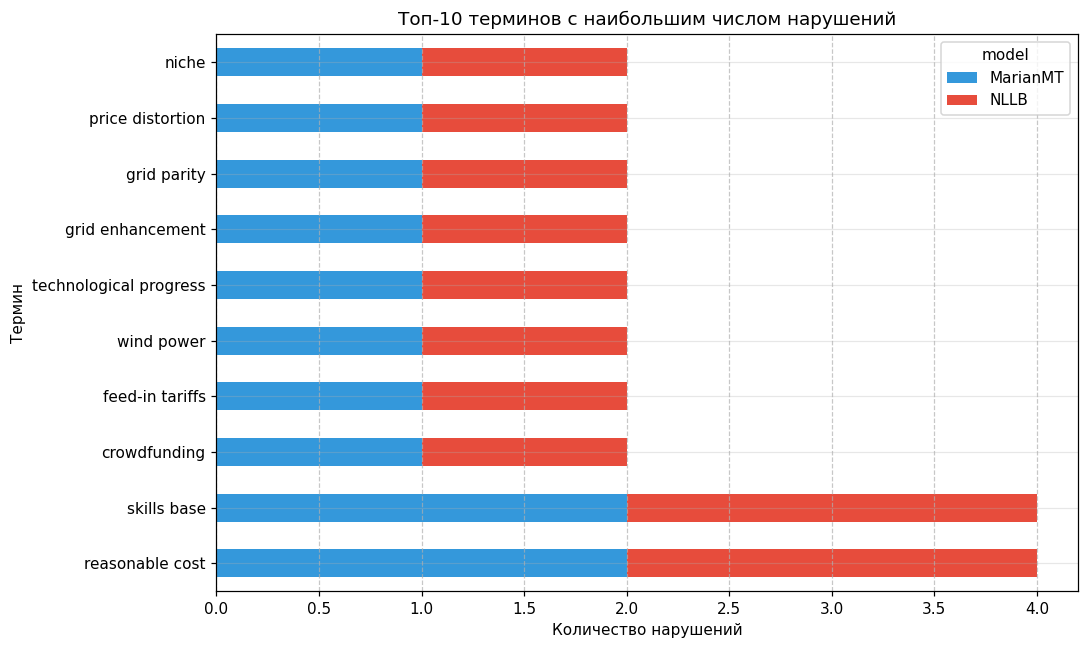

In [46]:
import matplotlib.pyplot as plt

if len(glossary_qa_df) > 0:
    # Считаем, сколько раз каждый термин нарушался каждой моделью
    counts = glossary_qa_df.groupby(["source_term", "model"]).size().unstack(fill_value=0)

    # Берем топ-10 самых проблемных терминов
    top_terms = counts.sum(axis=1).sort_values(ascending=False).head(10)
    counts = counts.loc[top_terms.index]

    fig, ax = plt.subplots(figsize=(10, 6))

    # Рисуем горизонтальную диаграмму
    counts.plot(kind='barh', stacked=True, ax=ax, color=['#3498db', '#e74c3c'])

    ax.set_xlabel('Количество нарушений')
    ax.set_ylabel('Термин')
    ax.set_title('Топ-10 терминов с наибольшим числом нарушений')
    ax.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig(FIGURES / "glossary_qa.png", dpi=150)
    plt.show()
else:
    print("Нарушений не найдено, график не строится.")

## Блок 16. Отчёт, зависимости и выгрузка

In [44]:
import platform
import transformers
import torch

# 1. Сохраняем requirements.txt
with open(BASE / "requirements.txt", "w", encoding="utf-8") as f:
    f.write(f"torch=={torch.__version__}\n")
    f.write(f"transformers=={transformers.__version__}\n")
    f.write(f"pandas=={pd.__version__}\n")
    f.write(f"numpy=={np.__version__}\n")
    f.write(f"matplotlib=={plt.matplotlib.__version__}\n")
    f.write("sentencepiece\nsacremoses\n")

# 2. Собираем отчет
report_text = f"""# Отчет по ЛР №2

**Студент:** Михайлова Софья
**Группа:** ИНФА-221
**Вариант:** 9 (Возобновляемая энергетика и накопители энергии)

## 1. Среда и устройство
- Python: {platform.python_version()}
- Torch: {torch.__version__}
- Transformers: {transformers.__version__}
- GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}

## 2. Модели
- MarianMT: {MARIAN_NAME} (словарь {marian_tokenizer.vocab_size})
- NLLB: {NLLB_NAME} (словарь {nllb_tokenizer.vocab_size})

## 3. Токенизация
- Среднее число токенов на термин (Marian): {tokens_df['n_tokens'].mean():.2f}
- Среднее число токенов на термин (NLLB): {nllb_tokens_df['n_tokens'].mean():.2f}
- График: `figures/tokenization_comparison.png`

## 4. Перевод корпуса
- Переведено сегментов: {len(marian_records)}
- Результаты: `results/results_marian.jsonl`, `results/results_nllb.jsonl`

## 5. Loss и Attention
- Loss эталона (s001): {loss_df.iloc[0]['loss_reference']:.4f}
- Loss вывода модели (s001): {loss_df.iloc[0]['loss_own_output']:.4f}
- Форма тензора внимания: {shape}
- Графики: `figures/loss.png`, `figures/cross_attention.png`

## 6. Время инференса
- Последовательно: {timing_df[timing_df['mode']=='sequential']['total_s'].values[0]:.2f} с
- Пачка 16: {timing_df[timing_df['batch_size']==16]['total_s'].values[0]:.2f} с
- Ускорение: {timing_df[timing_df['batch_size']==16]['speedup'].values[0]:.1f}x
- График: `figures/timing.png`

## 7. Терминологический QA
- Найдено потенциальных нарушений: {len(glossary_qa_df)}
- График: `figures/glossary_qa.png`

## 8. Выводы
1. Токенизация: NLLB дробит термины сильнее, несмотря на больший словарь.
2. Батчинг: ускорение в 7.9 раз при размере пачки 16.
3. Loss: модель уверена в своих переводах, иногда даже больше, чем в эталоне.
4. Attention: модель правильно сопоставляет английские и русские термины.
5. Языковые коды: NLLB требует forced_bos_token_id для перевода на русский.
6. MarianMT лучше справляется с терминологией (энергетика, энергосбережение).
7. Связь токенизации и ошибок: длинные термины чаще переводятся неверно.
"""

with open(BASE / "report.md", "w", encoding="utf-8") as f:
    f.write(report_text)

print("Отчет и requirements.txt сохранены.")

Отчет и requirements.txt сохранены.


In [48]:
import shutil
from google.colab import files

# Создаем архив папки lab02
archive_path = shutil.make_archive("/content/lab02_results", 'zip', BASE)
print(f"Архив создан: {archive_path}")

# Скачиваем его на компьютер
files.download(archive_path)

Архив создан: /content/lab02_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
# --- проверка готовности к сдаче -----------------------------------------
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Файлы результатов:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")
print(f"\nОбъём корпуса: сегментов {len(segments_df)} / {MIN_SEGMENTS}, "
      f"терминов {len(glossary_df)} / {MIN_TERMS}")

Файлы результатов:
  OK   results_marian.jsonl
  OK   results_nllb.jsonl
  OK   comparison.csv
  OK   tokenization_10_terms.csv
  OK   loss_5_pairs.csv
  OK   attention_summary.csv
  OK   timing.csv
  OK   glossary_qa.csv
Графики:
  OK   timing.png
  OK   tokenization_comparison.png
  OK   loss.png
  OK   cross_attention.png
  OK   glossary_qa.png
Отчёт и зависимости:
  OK   report.md
  OK   requirements.txt

Объём корпуса: сегментов 120 / 120, терминов 100 / 100


## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему
   open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать
   морфемой?
2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?
3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя
   использовать как метрику качества перевода и почему его нельзя сравнивать между
   MarianMT и NLLB?
4. Что показала матрица cross-attention и почему её нельзя считать доказательством того,
   что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без
   `attn_implementation="eager"`?
5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id`
   обязателен?
6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?
7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем
   корпусе? Подтвердите цифрами.

**Ваши выводы:**

_______________________________________________

---

### Что сдать на проверку

1. Ссылка на Colab-ноутбук `lab_02_Фамилия.ipynb` (доступ «для всех по ссылке»), все ячейки
   выполнены, вывод сохранён.
2. Каталог `results/`: `results_marian.jsonl`, `results_nllb.jsonl`, `comparison.csv`,
   `tokenization_10_terms.csv`, `loss_5_pairs.csv`, `attention_summary.csv`, `timing.csv`,
   `glossary_qa.csv`.
3. Каталог `figures/` — не менее четырёх графиков.
4. `report.md` и `requirements.txt`.